# Demostration of ICAROS

## The purpose of this NB is: 

- Selecting events.

- Checking run conditions are normal.

- Computing XY correction maps.


There are **some differences** with <font color='navy'>*official_map_builder_NB.ipynb*</font>:
    
   1. Here the map is only computed function-by-function (i.e. the automatic script is not used).
   
   2. The different distributions are not compared with other references.
   
   3. There are three possibilities for the band selection:  No band selection / Usual selection using a bootstrap map / Manual

## It is divided into two main sections:

1. __Section A:__ Map building showing the different steps that the script follows

2. __Section B:__ In case the map is produced, map checking.

****

# Section A: Map building

In [1]:
import sys
sys.path.append('/scratch/marian/IC')

In [2]:
import os
import logging
import warnings

import numpy  as np
import glob
import matplotlib.pyplot as plt

from krcal.core.kr_types                      import masks_container
from krcal.map_builder.map_builder_functions  import calculate_map
from krcal.core.kr_types                      import FitType
from krcal.core.fit_functions                 import expo_seed
from krcal.core.selection_functions           import selection_in_band
from krcal.map_builder.map_builder_functions  import e0_xy_correction

from krcal.map_builder.map_builder_functions  import check_failed_fits
from krcal.map_builder.map_builder_functions  import regularize_map
from krcal.map_builder.map_builder_functions  import remove_peripheral
from krcal.map_builder.map_builder_functions  import add_krevol
from invisible_cities.reco.corrections        import read_maps
from krcal.core.io_functions                  import write_complete_maps

from krcal.NB_utils.xy_maps_functions         import draw_xy_maps
from krcal.core    .map_functions             import relative_errors
from krcal.core    .map_functions             import add_mapinfo

from krcal.NB_utils.plt_functions             import plot_s1histos, plot_s2histos
from krcal.NB_utils.plt_functions             import s1d_from_dst, s2d_from_dst
from krcal.NB_utils.plt_functions             import plot_selection_in_band

from invisible_cities.core.configure          import configure
from invisible_cities.io.dst_io               import load_dst, load_dsts
from invisible_cities.core.core_functions     import in_range
from invisible_cities.core.core_functions     import shift_to_bin_centers
from invisible_cities.core.fit_functions      import profileX

In [3]:
font_size = 10

# Configure matplotlib
plt.rcParams['font.family'] = 'serif'
plt.rcParams['mathtext.fontset'] = 'cm'
plt.rcParams['font.size'] = font_size

# Line properties
plt.rcParams['lines.linewidth'] = 2.5  # Default line width
plt.rcParams['lines.markersize'] = 8   # Default marker size
plt.rcParams['lines.linestyle'] = '-'  # Default line style
plt.rcParams['lines.marker'] = None    # Default marker (None for no marker)
plt.rcParams['lines.markeredgewidth'] = 1.0  # Marker edge width

# Set default color cycle (replaces the default light colors)
# colors = ['deepskyblue', 'lightcoral', 'darkseagreen', 'plum', 'blue']  # Define a list of colors
colors = ['deepskyblue', 'lightcoral', 'darkseagreen', 'plum', 'blue']  # Define a list of colors
# plt.rcParams['axes.prop_cycle'] = plt.cycler(color=colors)

*Set input/output variables and configuration file*

In [4]:
run_number = 0 # 0 or negative for MC

In [5]:
# input_folder       = f'/media/gonzalo/se/data/NEXT/4bar/kr/kdst/'
# input_folder       = f'/scratch/marian/ic-course/data/'
# input_dst_file     = '20250624_Next100_1Kev_ELoff_Kr_ALL_PMTs.dorothea.h5'
# input_dsts         = glob.glob(input_folder + input_dst_file)

input_folder       = f'/scratch/marian/IC/outputs/'
input_dst_file     = '20250626_Next100_50Kev_ELoff_Kr_0-40.dorothea.h5'
input_dsts         = glob.glob(input_folder + input_dst_file)

output_maps_folder = '.'

map_file_out     = os.path.join(output_maps_folder, f'20250626_Next100_50Kev_ELoff_Kr_0-40_map_{run_number}.h5')
histo_file_out   = os.path.join(output_maps_folder, f'hists_{run_number}_test.h5')

print('Input dst: ', input_folder + input_dst_file)
print('Number of dsts: ', len(input_dsts))
print('Output map file: ', map_file_out)
print('Output histograms file: ', histo_file_out)

Input dst:  /scratch/marian/IC/outputs/20250626_Next100_50Kev_ELoff_Kr_0-40.dorothea.h5
Number of dsts:  1
Output map file:  ./20250626_Next100_50Kev_ELoff_Kr_0-40_map_0.h5
Output histograms file:  ./hists_0_test.h5


which band selection do you want to be applied?

- None

- bootstrap

- manual

To illustrate, the three methods have been tested for run 7751, and the energy resolution at the Krypton peak obtained was:

- "None"      : 4.026 %
- "manual"    : 3.962 %
- "bootrstrap": 3.976 %

In [6]:
band_selection = 'None'
if band_selection=='None': print('No selection will be made')
elif band_selection=='manual': print('The band selection will be applied manually')
elif band_selection=='bootstrap':
    bootstrap_filename = '/home/ausonandres/IC/invisible_cities/database/test_data/kr_emap_xy_100_100_r_6573_time.h5'
    bootstrapmap = read_maps(bootstrap_filename)
    print(f'Bootstrap map: {bootstrap_filename}')
    draw_xy_maps(bootstrapmap)

No selection will be made


#### Loading data (only events inside detector chamber; i.e. R<=200)

In [7]:
input_dsts

['/scratch/marian/IC/outputs/20250626_Next100_50Kev_ELoff_Kr_0-40.dorothea.h5']

In [8]:
dst = load_dsts(input_dsts, 'DST', 'Events')
dst = dst.loc[in_range(dst.R, 0, 500)]
dst = dst.sort_values('time')

filename = /scratch/marian/IC/outputs/20250626_Next100_50Kev_ELoff_Kr_0-40.dorothea.h5
table = <class 'tables.table.Table'>


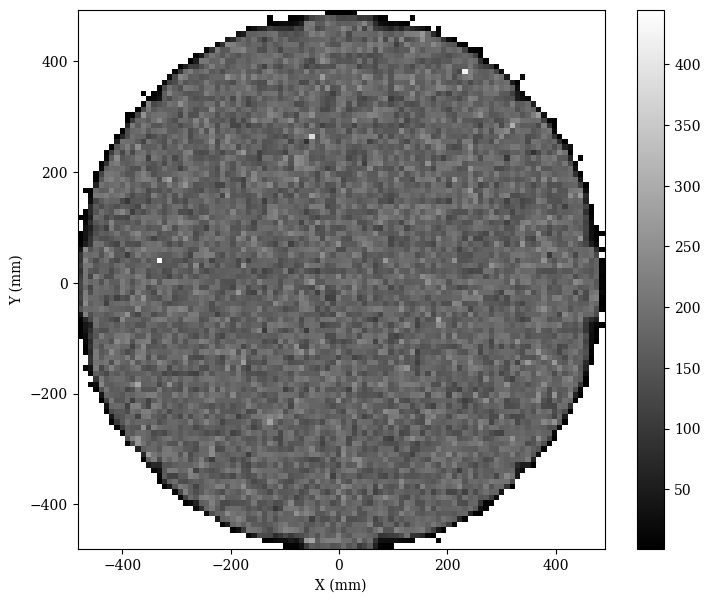

In [9]:
plt.figure(figsize=(8.5, 7));
plt.hist2d(dst.X, dst.Y, 100, cmin=1, cmap="gray");
plt.xlabel('X (mm)');
plt.ylabel('Y (mm)');
plt.colorbar();

### Rate before selections

In [10]:
if run_number:
    plt.figure(figsize=(10, 6));
    plt.hist(dst.time, 100, histtype='step', color='k', linewidth=1.3)
    plt.xlabel('Timestamps (s)');
    plt.ylabel('Events');
    plt.title('Event rate');

## Event selection

### nS1 selection

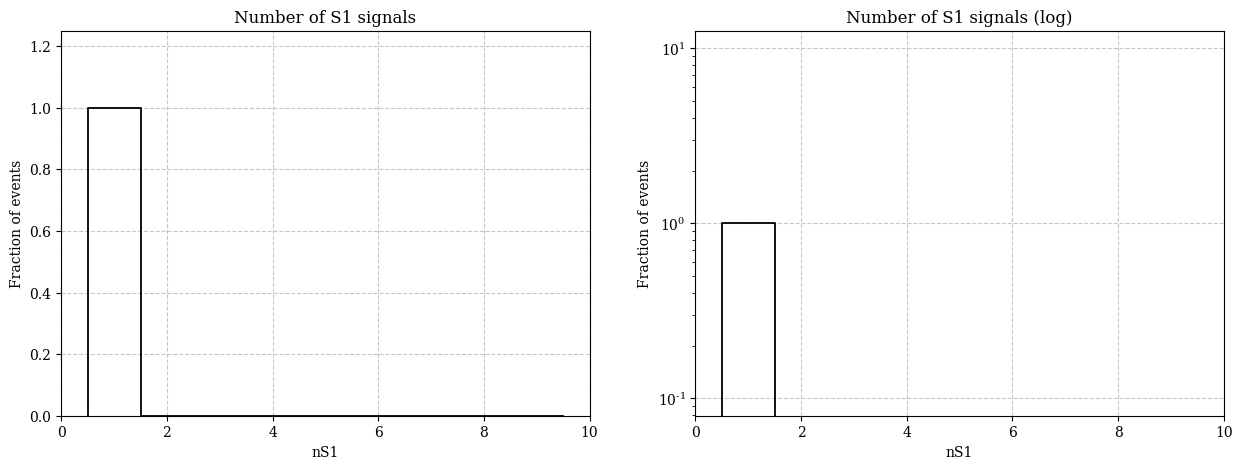

In [11]:
plt.figure(figsize=(15,5));
plt.subplot(121);
y, x = np.histogram(dst.drop_duplicates(subset='event').nS1, 10, (0, 10))
plt.step(shift_to_bin_centers(x), y/dst.event.nunique(), color='k', linewidth=1.3)
plt.xlim(0, 10);
plt.ylim(0, 1.25);
plt.grid(True, alpha=0.7, linestyle='--');
plt.xlabel('nS1');
plt.ylabel('Fraction of events');
plt.title('Number of S1 signals');
plt.subplot(122);
plt.step(shift_to_bin_centers(x), y/dst.event.nunique(), color='k', linewidth=1.3)
plt.xlim(0, 10);
plt.xlabel('nS1');
plt.ylabel('Fraction of events');
plt.title('Number of S1 signals (log)');
plt.yscale('log');
plt.grid(True, alpha=0.7, linestyle='--');

In [12]:
eff = dst[dst.nS1==1].event.nunique()/dst.event.nunique()
print('S1 selection efficiency: ', eff*100, '%')

S1 selection efficiency:  100.0 %


In [13]:
mask_s1 = dst.nS1==1

*Some other S1 plots:*

/scratch/marian/ICAROS/krcal/core/stat_functions.py:29: UserWarning: warning, empty slice of x = [100000. 100000. 100000. ... 100000. 100000. 100000.] in range = (0, 600)
  warnings.warn(f'warning, empty slice of x = {x} in range = {range_}')


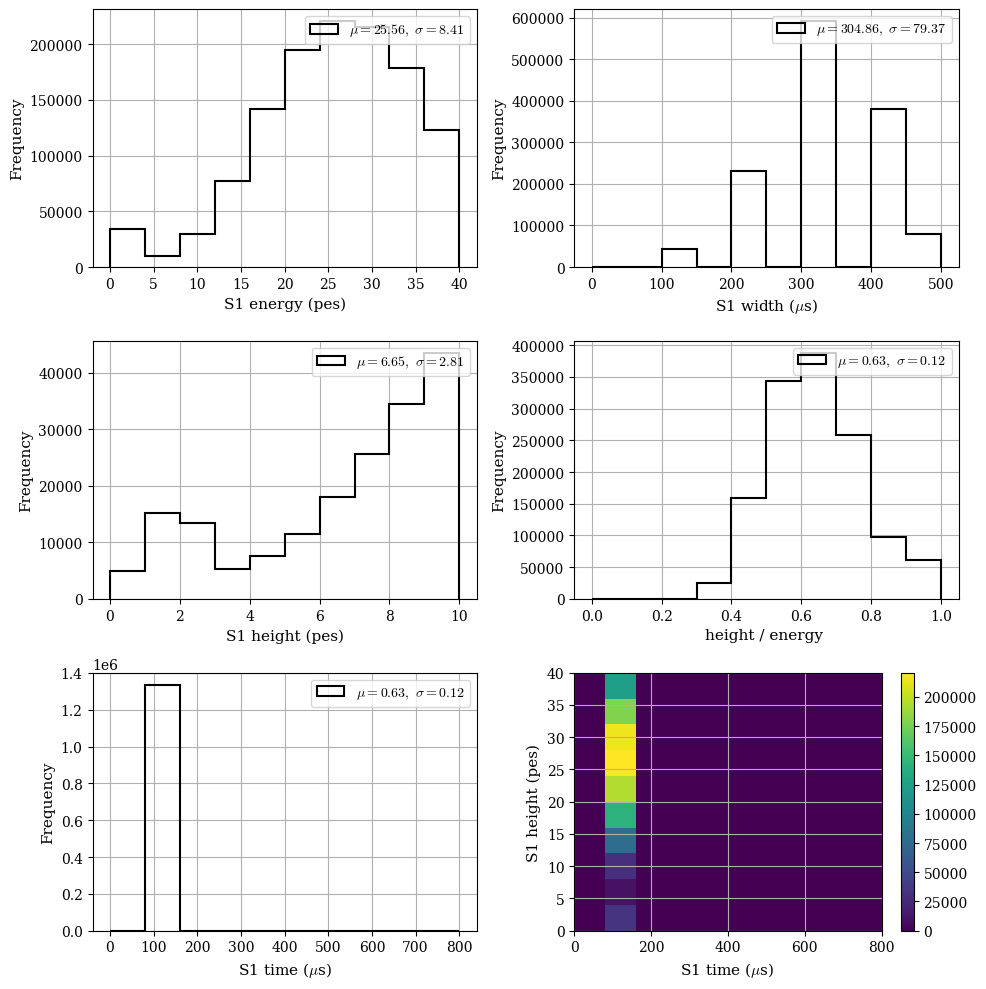

In [14]:
s1d = s1d_from_dst(dst)
plot_s1histos(dst,  s1d, bins=10, figsize=(10,10))

### nS2 selection

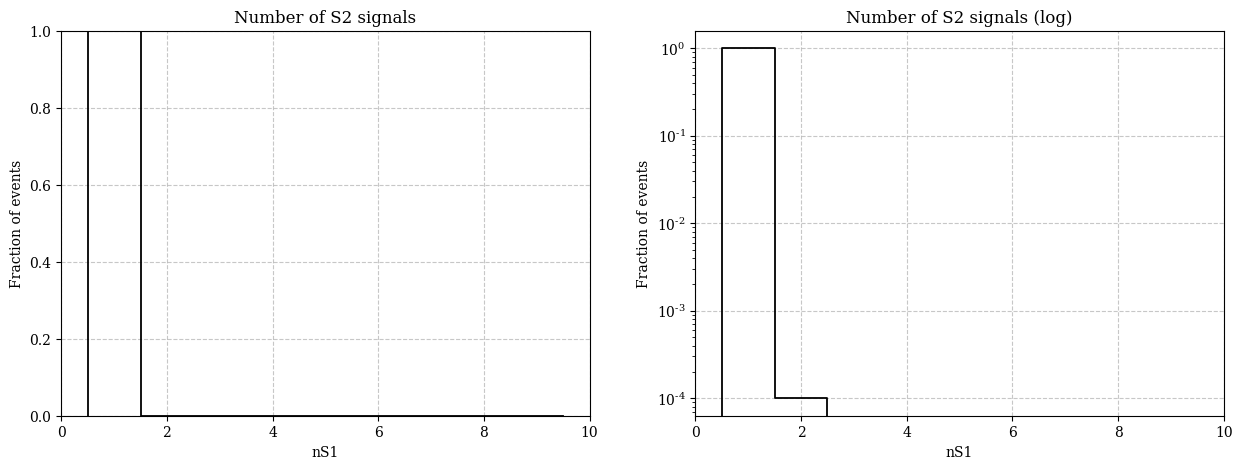

In [15]:
plt.figure(figsize=(15,5));
plt.subplot(121);
y, x = np.histogram(dst[mask_s1].drop_duplicates(subset='event').nS2, 10, (0, 10))
plt.step(shift_to_bin_centers(x), y/dst[mask_s1].event.nunique(), color='k', linewidth=1.3)
plt.xlim(0, 10);
plt.ylim(0, 1);
plt.grid(True, alpha=0.7, linestyle='--');
plt.xlabel('nS1');
plt.ylabel('Fraction of events');
plt.title('Number of S2 signals');
plt.subplot(122);
plt.step(shift_to_bin_centers(x), y/dst[mask_s1].event.nunique(), color='k', linewidth=1.3)
plt.xlim(0, 10);
plt.xlabel('nS1');
plt.ylabel('Fraction of events');
plt.title('Number of S2 signals (log)');
plt.yscale('log');
plt.grid(True, alpha=0.7, linestyle='--');

In [16]:
mask_s2 = np.zeros_like(mask_s1)
mask_s2[mask_s1] = dst[mask_s1].nS2 == 1
nevts_after      = dst[mask_s2].event.nunique()
nevts_before     = dst[mask_s1].event.nunique()
eff              = nevts_after / nevts_before
print('S2 selection efficiency: ', eff*100, '%')

S2 selection efficiency:  100.0 %


*Some other S2 plots:*

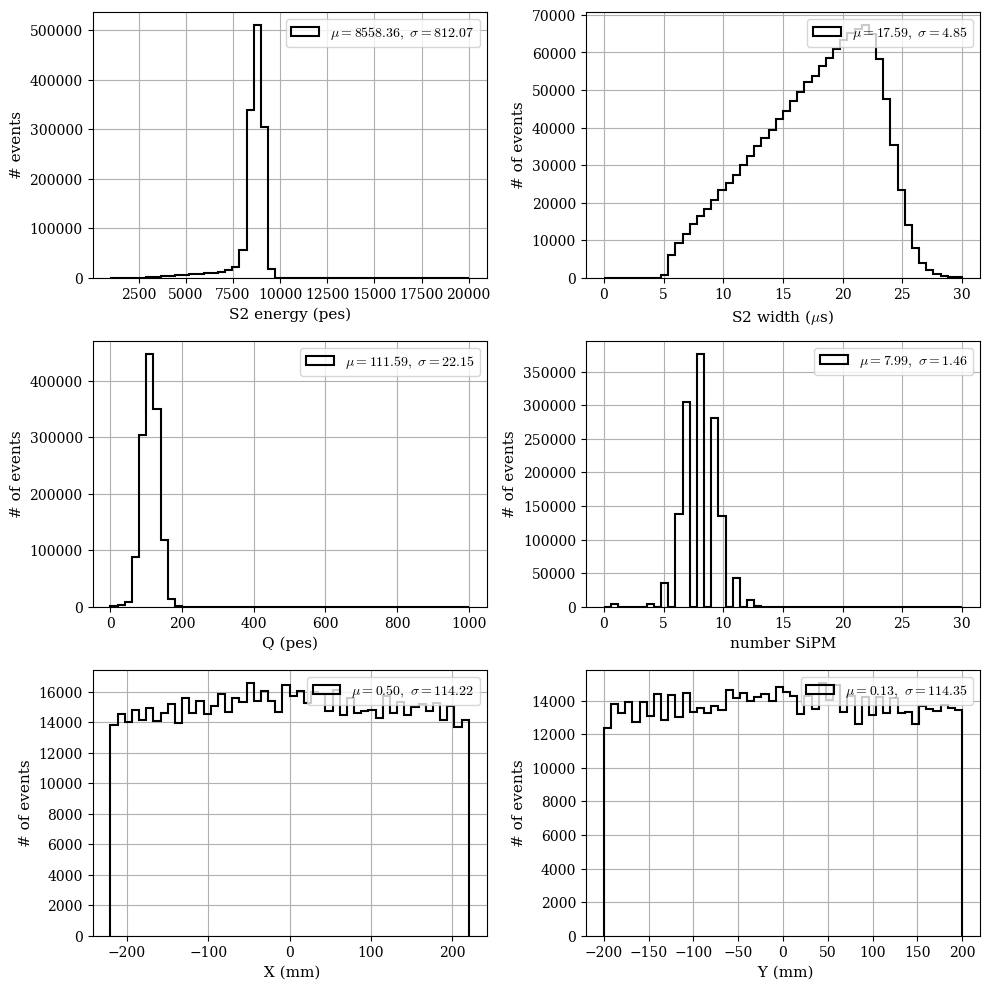

In [17]:
s2d = s2d_from_dst(dst[mask_s1])
plot_s2histos(dst, s2d, bins=50, emin=1000, emax=20000, figsize=(10,10))

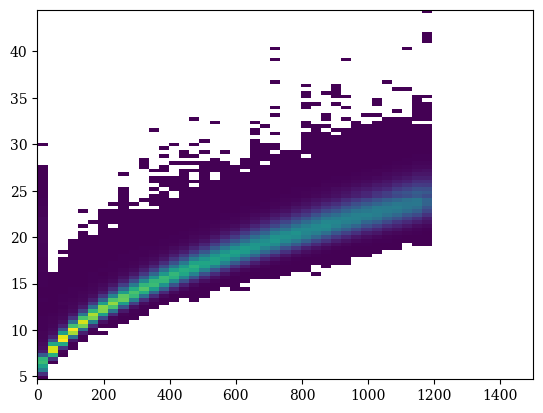

In [18]:
plt.hist2d(dst.Z, dst.S2w, (np.linspace(0, 1500), 100), cmin=1);


### Band selection

In [19]:
z_range_plot = (0, 1200)
e_range_plot = (0, 20000)

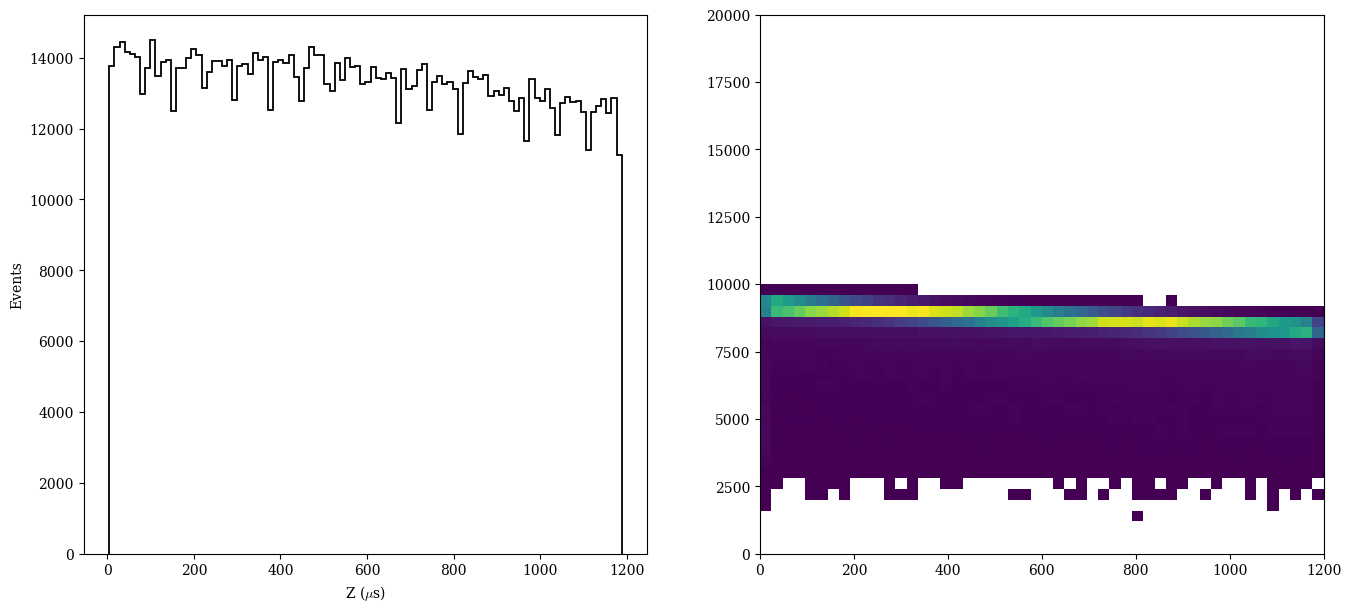

In [20]:
plt.figure(figsize=(16, 7));
plt.subplot(121);
plt.hist(dst[mask_s2].Z, 100, histtype='step', linewidth=1.3, color='k');
plt.xlabel(r'Z ($\mu$s)');
plt.ylabel('Events');
plt.subplot(122);
plt.hist2d(dst[mask_s2].Z, dst[mask_s2].S2e, 50, [z_range_plot, e_range_plot], cmin=1);

In [21]:
if band_selection=='None':
    sel_krband = mask_s2

In [22]:
if band_selection=='manual':
    x, y, _ = profileX(dst[mask_s2].Z, dst[mask_s2].S2e, yrange=e_range_plot)
    e0_seed, lt_seed = expo_seed(x, y)
    lower_e0, upper_e0 = e0_seed-4000, e0_seed+2000    # play with these values to make the band broader or narrower
    
    plt.figure(figsize=(8, 5.5))
    xx = np.linspace(z_range_plot[0], z_range_plot[1], 100)
    plt.hist2d(dst[mask_s2].Z, dst[mask_s2].S2e, 50, [z_range_plot, e_range_plot], cmin=1);
    plt.plot(xx, (lower_e0)*np.exp(xx/lt_seed), color='red', linewidth=1.7)
    plt.plot(xx, (upper_e0)*np.exp(xx/lt_seed), color='red', linewidth=1.7)
    plt.xlabel(r'Z ($\mu$s)');
    plt.ylabel('S2e (pes)');
    
    sel_krband = np.zeros_like(mask_s2)
    Zs = dst[mask_s2].Z
    sel_krband[mask_s2] = in_range(dst[mask_s2].S2e, (lower_e0)*np.exp(Zs/lt_seed), (upper_e0)*np.exp(Zs/lt_seed))

In [23]:
if band_selection=='bootstrap':
    
    band_sel_params = dict(
    range_z = (10, 550)      ,
    range_e = (10.0e+3,14e+3),
    nbins_z = 50             ,
    nbins_e = 50             ,
    nsigma  = 3.5            )
    
    geom_corr = e0_xy_correction(bootstrapmap)
    corr = geom_corr(dst[mask_s2].X.values, dst[mask_s2].Y.values)
    E0   = dst[mask_s2].S2e.values * corr
    
    sel_krband = np.zeros_like(mask_s2)
    sel_krband[mask_s2], fpl, fph, hp, pp = selection_in_band(dst[mask_s2].Z, E0, **band_sel_params)
    print('Band selection efficiency: ', dst[sel_krband].event.nunique()/dst[mask_s2].event.nunique()*100, '%')
    
    plot_selection_in_band(fpl, fph, hp, pp, nsigma = band_sel_params['nsigma'])

In [24]:
if band_selection!='None':
    plt.figure(figsize=(16, 7));
    plt.subplot(121);
    plt.hist2d(dst[mask_s2].Z, dst[mask_s2].S2e, 50, [z_range_plot, e_range_plot], cmin=1);
    plt.xlabel(r'Z ($\mu$s)');
    plt.ylabel('S2e (pes)');
    plt.title('Before band selection')
    plt.subplot(122);
    plt.hist2d(dst[sel_krband].Z, dst[sel_krband].S2e, 50, [z_range_plot, e_range_plot], cmin=1);
    plt.xlabel(r'Z ($\mu$s)');
    plt.ylabel('S2e (pes)');
    plt.title('After band selection')

In [25]:
sel_dst = dst[sel_krband]

#### Post-selection distributions

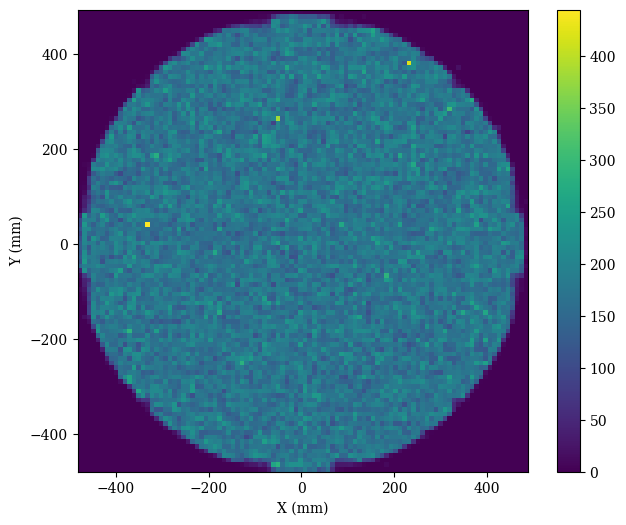

In [26]:
plt.figure(figsize=(16, 6));
plt.subplot(121);
plt.hist2d(sel_dst.X, sel_dst.Y, 100);
plt.xlabel('X (mm)');
plt.ylabel('Y (mm)');
plt.colorbar();
if run_number:
    plt.subplot(122);
    plt.hist(dst.time, 100, alpha=0.5, color='grey', label='pre-cuts')
    plt.hist(sel_dst.time, 100, histtype='step', color='k', linewidth=1.3, label='post-cuts')
    plt.legend(shadow=True, loc='lower center');
    plt.xlabel('Timestamps (s)');
    plt.ylabel('Events');
    plt.title('Event rate');

## Map production

#### Selection of number of XY bins

Number of XY bins commonly used (in NEW);
- If the number of selected evts is greater than 1e6 -> 100x100 map
- If the number of selected evts is lower than 1e6 -> 50x50 map

In [27]:
print(sel_dst.event.nunique(), 'events')

50000 events


In [28]:
number_of_bins = 20
print('Number of XY bins: ', number_of_bins)

Number of XY bins:  20


### Map computation

In [29]:
map_params = {'nbins_z': 50,
              'nbins_e': 100,
              'z_range': (150, 1000),
              'e_range': (7500, 20000),
              'chi2_range': (0, 1000),
              'lt_range': (7000, 80000),
              'nmin': 5,
              'maxFailed': 10000,
              'r_max': 500,
              'r_fid': 100,
              'nStimeprofile': 1800,
              'x_range': (-500, 500),
              'y_range': (-500, 500)}

In [30]:
warnings.filterwarnings("ignore")
logging.disable(logging.DEBUG)
this_script_logger = logging.getLogger(__name__)
this_script_logger.setLevel(logging.INFO)

In [31]:
maps = calculate_map(dst        = sel_dst                 ,
                     XYbins     = (number_of_bins         ,
                                   number_of_bins)        ,
                     nbins_z    = map_params['nbins_z']   ,
                     nbins_e    = map_params['nbins_e']   ,
                     z_range    = map_params['z_range']   ,
                     e_range    = map_params['e_range']   ,
                     chi2_range = map_params['chi2_range'],
                     lt_range   = map_params['lt_range']  ,
                     fit_type   = FitType.unbined         ,
                     nmin       = map_params['nmin']      ,
                     x_range    = map_params['x_range']   ,
                     y_range    = map_params['y_range']   )

### Last check: number of failed fits

In [32]:
maxFailed = map_params['maxFailed']
r_max     = map_params['r_max']

check_failed_fits(maps      = maps          ,
                  maxFailed = maxFailed     ,
                  nbins     = number_of_bins,
                  rmax      = r_max         ,
                  rfid      = r_max         )

    Number of failing fits: 0


#### chi2 regularization and compute relative error maps, instead of absolute error.

In [33]:
regularized_maps = regularize_map(maps    = maps                    ,
                                  x2range = map_params['chi2_range'])

regularized_maps = relative_errors(am = regularized_maps)

Now, the outer bins are replaced by nans:

In [34]:
regularized_maps = remove_peripheral(map   = regularized_maps,
                                     nbins = number_of_bins  ,
                                     rmax  = r_max           ,
                                     rfid  = r_max           )

In [35]:
regularized_maps.lt

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
0,NaN,NaN,NaN,NaN,NaN,NaN,11495.684248,5467.060070,5040.418869,4931.378956,7227.571206,6512.748534,4898.605328,9817.075710,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,26133.341565,5346.320057,5357.202997,8782.324464,10631.169478,10527.951165,10655.793221,10871.038141,8536.077527,5808.827944,5773.995181,53803.211657,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,6493.342100,5514.326772,9458.499273,11770.401880,11786.833358,11748.652617,11922.461696,11991.598269,12476.553482,12524.541324,11873.119250,9781.457225,5679.890451,13125.789650,NaN,NaN,NaN
3,NaN,NaN,8547.153129,6991.309878,11207.872748,12065.040910,11932.723802,11715.611747,11687.483854,12007.924802,11959.775308,12046.312835,11746.789131,12375.788697,11774.411058,11623.353349,7341.565449,6850.421402,NaN,NaN
4,NaN,-111236.267656,5592.321166,11003.246140,11933.503885,11984.021100,11777.987355,11757.086060,12096.963667,12291.974814,12001.967009,11802.666575,12085.254014,12022.803439,12018.348158,12018.662214,11210.835816,6343.813720,4479.247728,NaN
5,NaN,4715.216204,10614.422291,11624.000167,11966.621789,11900.718183,12132.460777,11596.727006,11904.049752,12029.520122,11890.429046,11925.525987,11954.974524,12010.466790,11822.309743,12053.185113,11738.419806,8562.600732,11742.647717,NaN
6,5213.594156,7187.812741,12119.451354,12069.748230,11883.113081,11894.903705,12227.618631,12165.293210,11888.447672,12037.420578,12040.594998,11898.610674,11872.167066,11862.250010,11976.612448,12172.887498,11993.107958,11958.767280,7873.413671,9817.075710
7,5365.376084,7945.529487,11949.350895,11711.294345,11861.198414,12034.826639,11912.799265,11925.830587,11621.256163,11857.176836,11804.914372,11980.061511,12184.062780,12276.682817,12158.451246,12285.404947,11851.808229,12098.424466,7941.236552,4379.518227
8,5092.781140,11005.856221,12128.887363,12125.700011,11882.619369,12051.768119,12077.613647,12098.466576,11731.207057,11976.849296,11788.094139,11701.771297,11984.073637,11893.000448,12323.308032,11930.306727,11630.278452,12401.696904,10201.547724,9817.075710
9,9959.856895,11308.098430,11660.301918,11619.517571,12066.363124,11914.475878,11943.760615,12238.029100,12532.683524,11716.840778,11970.699553,12368.245827,11860.397153,11990.993672,11873.517292,11664.014436,12111.819649,11993.232726,10835.616544,6397.998037


In [36]:
regularized_maps.ltu.max()


0     0.486528
1     0.617561
2     0.365298
3     0.471777
4     0.746841
5     0.203486
6     0.938195
7     0.376866
8     0.241989
9     0.236137
10    0.231722
11    0.270502
12    0.350395
13    0.643266
14    0.218142
15    0.531418
16    0.455107
17    0.290902
18    0.633850
19    0.537357
dtype: float64

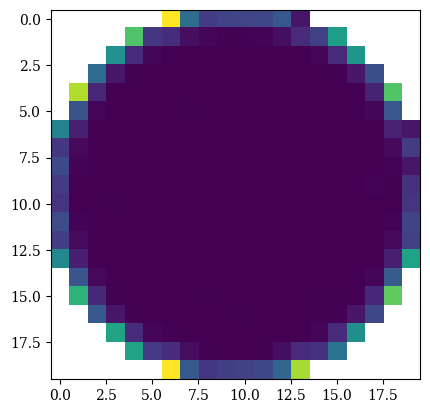

In [37]:
plt.imshow(regularized_maps.e0u.values, vmax=1e-1)

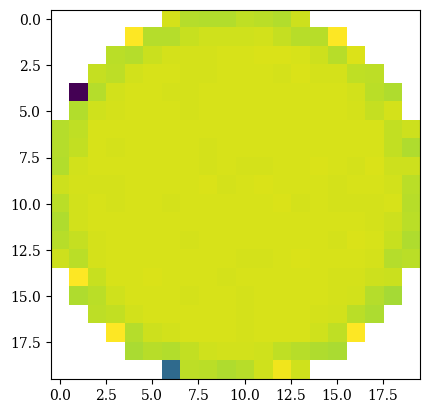

In [38]:
plt.imshow(regularized_maps.lt.values, vmax=20e3)

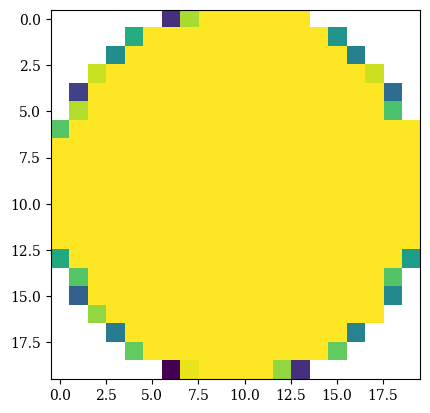

In [39]:
plt.imshow(regularized_maps.e0.values, vmax=7e3)

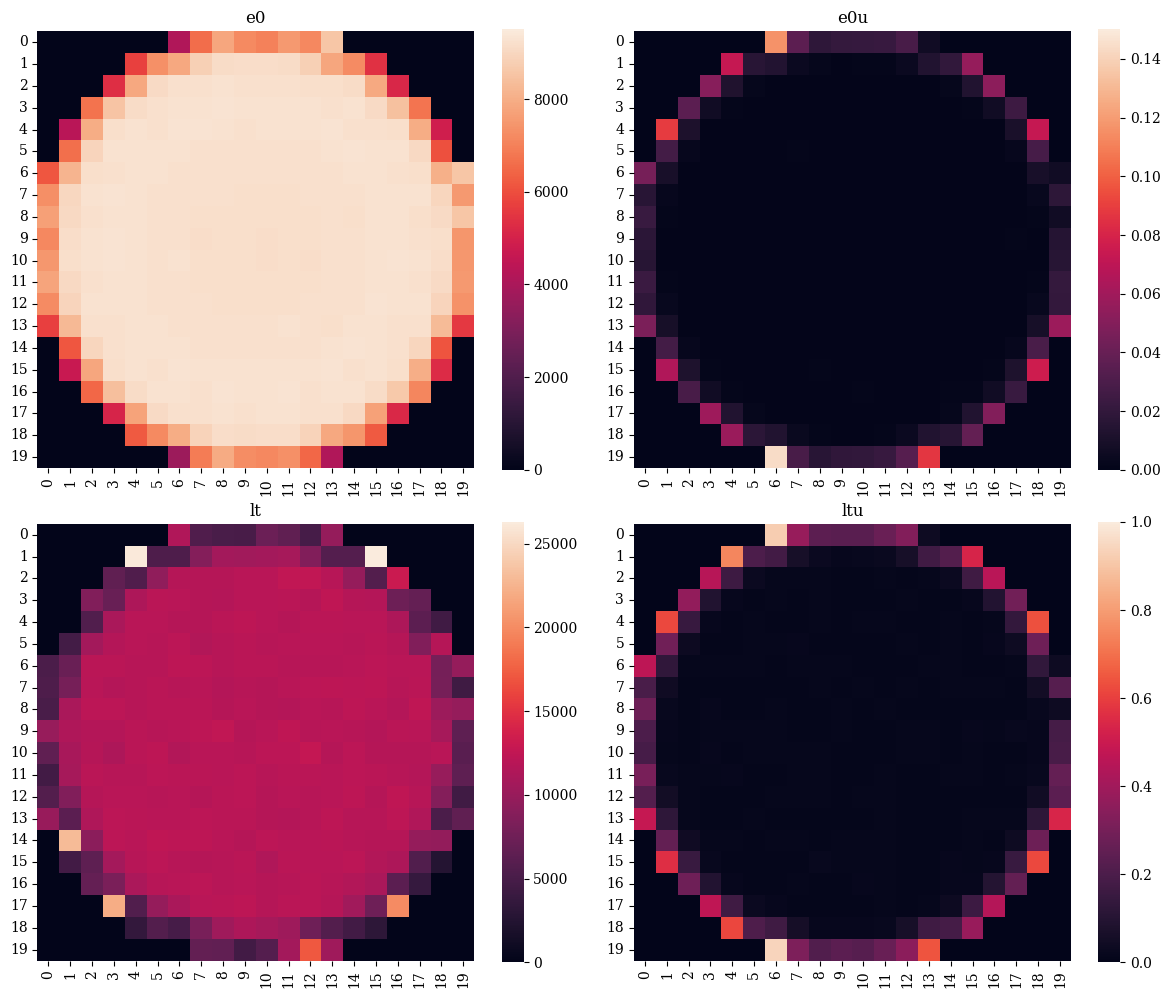

In [40]:
draw_xy_maps(regularized_maps,
             e0lims = (0, 9.5e3),
             eulims = (0, 1.5e-1),
             ltlims = (0, 26.3e3),
             lulims = (0, 1e0),
             figsize=(12,10))

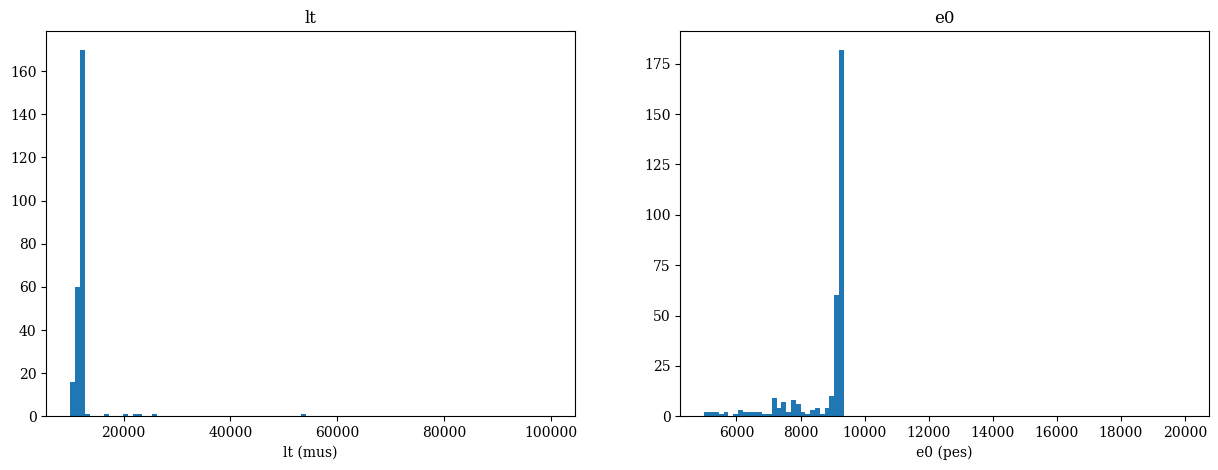

In [41]:
plt.figure(figsize=(15, 5))
plt.subplot(121)
plt.hist(regularized_maps.lt.values.flatten(), 100, (10000, 100000));
plt.title('lt')
plt.xlabel('lt (mus)');
plt.subplot(122)
plt.hist(regularized_maps.e0.values.flatten(), 100, (5000, 20000));
plt.title('e0')
plt.xlabel('e0 (pes)');

#### Mapinfo table is added

In [42]:
maps = add_mapinfo(asm        = regularized_maps     ,
                   xr         = map_params['x_range'],
                   yr         = map_params['y_range'],
                   nx         = number_of_bins       ,
                   ny         = number_of_bins       ,
                   run_number = run_number           )
print(maps.mapinfo)

xmin         -500
xmax          500
ymin         -500
ymax          500
nx             20
ny             20
run_number      0
dtype: int64


#### Temporal evolution table is added FOR DATA

In [43]:
if run_number>0:
    
    masks = masks_container(s1   = mask_s1,
                            s2   = mask_s2,
                            band = sel_krband)

    r_fid         = map_params['r_fid']
    nStimeprofile = map_params['nStimeprofile']
    add_krevol(maps          = maps                 ,
               dst           = dst                  ,
               masks_cuts    = masks                ,
               r_fid         = r_fid                ,
               nStimeprofile = nStimeprofile        ,
               x_range       = map_params['x_range'],
               y_range       = map_params['y_range'],
               XYbins        = (number_of_bins      ,
                                number_of_bins     ))
    temp = maps.t_evol

In [44]:
if run_number>0:
    plt.figure(figsize=(20, 15));
    plt.subplot(3,3,1);
    plt.title('e0');
    plt.errorbar(temp.ts, temp.e0, temp.e0u, fmt='.', linestyle='-');
    plt.subplot(3,3,2);
    plt.title('lt');
    plt.errorbar(temp.ts, temp['lt'], temp['ltu'], fmt='.', linestyle='-');
    plt.subplot(3,3,3);
    plt.title('dv');
    plt.ylim(0.907, 0.935);
    plt.errorbar(temp.ts, temp.dv, temp.dvu, fmt='.', linestyle='-');
    plt.subplot(3,3,4);
    plt.title('s1e');
    plt.errorbar(temp.ts, temp.s1e, temp.s1eu, fmt='.', linestyle='-');
    plt.subplot(3,3,5);
    plt.title('s2e');
    plt.errorbar(temp.ts, temp.s2e, temp.s2eu, fmt='.', linestyle='-');
    plt.subplot(3,3,6);
    plt.title('Nsipm');
    plt.errorbar(temp.ts, temp.Nsipm, temp.Nsipmu, fmt='.', linestyle='-');
    plt.subplot(3,3,7);
    plt.title('nS1 cut eff.');
    plt.errorbar(temp.ts, temp.S1eff, fmt='.', linestyle='-');
    plt.subplot(3,3,8);
    plt.title('nS2 cut eff.');
    plt.errorbar(temp.ts, temp.S2eff, fmt='.', linestyle='-');
    plt.subplot(3,3,9);
    plt.title('Band cut eff.');
    plt.errorbar(temp.ts, temp.Bandeff, fmt='.', linestyle='-');

### Writing final map

In [45]:
write_complete_maps(asm      = maps        ,
                    filename = map_file_out)

*****

# Section C: Checking map <a id='SectionC'></a>

In [46]:
print(f'Opening computed map: {map_file_out}')
final_map = read_maps(map_file_out)

Opening computed map: ./20250626_Next100_50Kev_ELoff_Kr_0-40_map_0.h5


In [47]:
from krcal.NB_utils.plt_functions             import h1, h2
from krcal.NB_utils.fit_energy_functions      import fit_energy
from krcal.NB_utils.plt_energy_functions      import plot_fit_energy, print_fit_energy
from krcal.NB_utils.plt_energy_functions      import resolution_r_z, plot_resolution_r_z
from invisible_cities.reco.corrections        import apply_all_correction

#### Applying correction to the selected dst

In [48]:
sel_dst = sel_dst[sel_dst.R<400]

In [49]:
geom_corr = e0_xy_correction(final_map)
if run_number>0: total_correction = apply_all_correction(final_map, apply_temp=True)
else:
    total_correction = apply_all_correction(final_map, apply_temp=False)
    print('Temporal corrections will not be applied since MC maps do not contain time-dependence information.')

corr_geo = geom_corr(sel_dst.X, sel_dst.Y)
corr_tot = total_correction(sel_dst.X, sel_dst.Y, sel_dst.Z, sel_dst.time)

Temporal corrections will not be applied since MC maps do not contain time-dependence information.


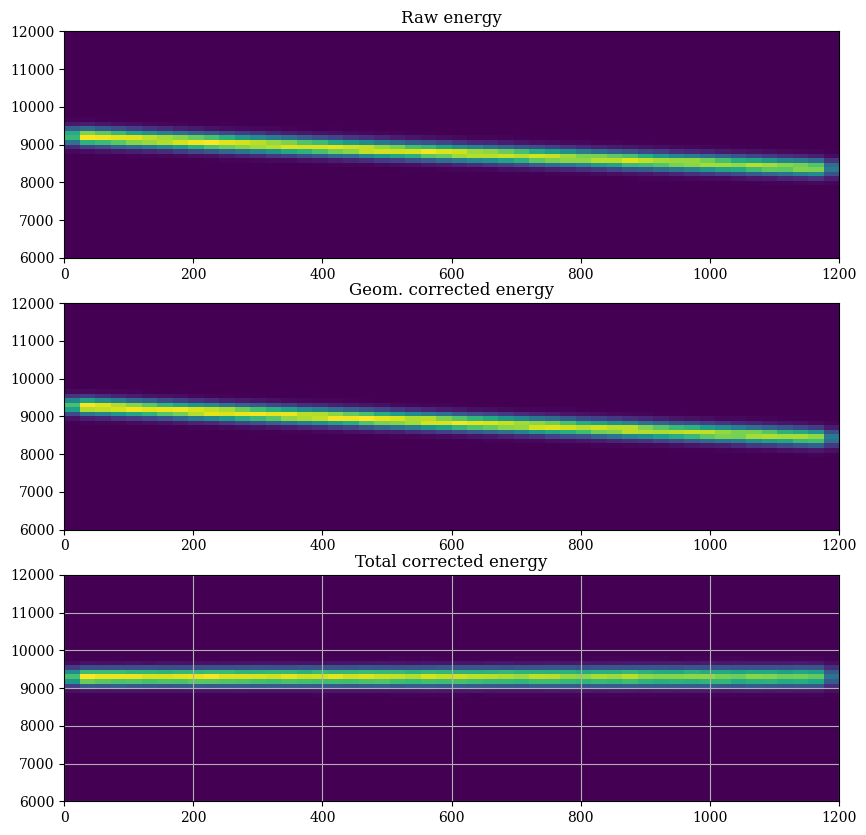

In [50]:
fig = plt.figure(figsize=(10,10))
plt.subplot(3, 1, 1)
plt.hist2d(sel_dst.Z, sel_dst.S2e, 50, [(0,1200),(6000,12000)])
plt.title(r'Raw energy');
plt.subplot(3, 1, 2)
plt.hist2d(sel_dst.Z, sel_dst.S2e*corr_geo, 50, [(0,1200),(6000,12000)])
plt.title(r'Geom. corrected energy');
plt.subplot(3, 1, 3)
plt.hist2d(sel_dst.Z, sel_dst.S2e*corr_tot, 50, [(0,1200),(6000,12000)])
plt.grid()
plt.title(r'Total corrected energy');

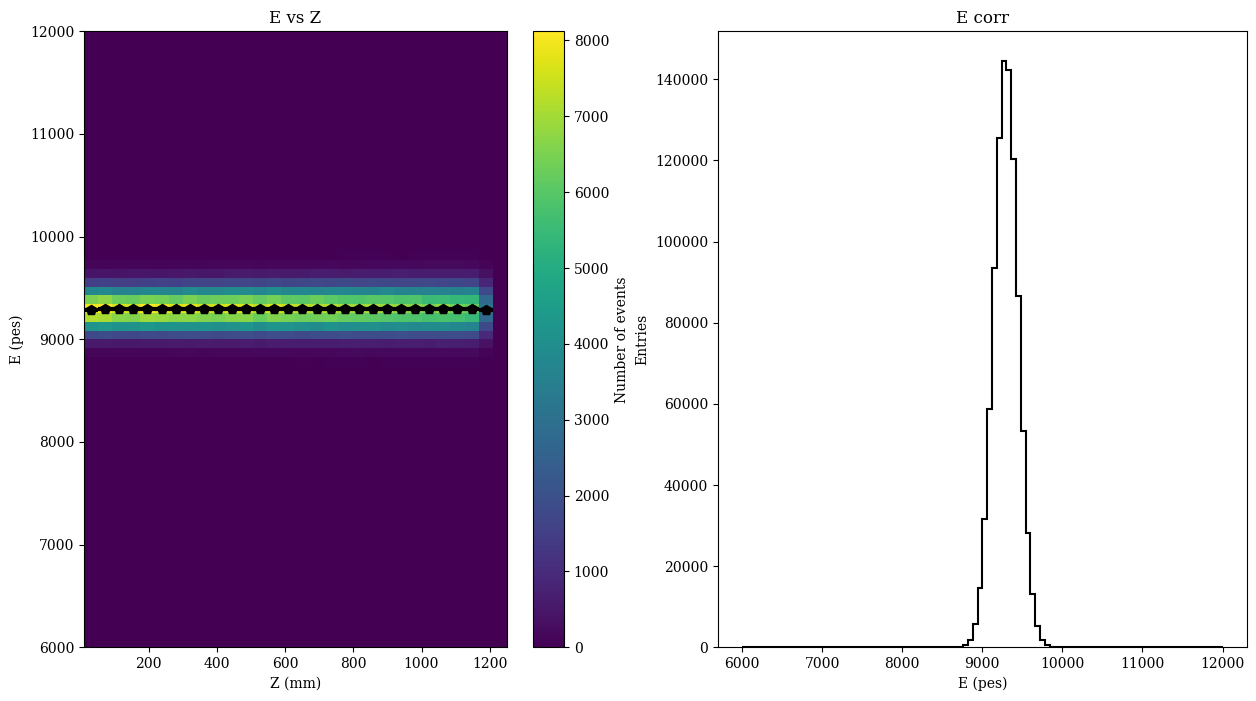

In [51]:
e_range = (6000,12000)
zrange = (10,1250)
fig = plt.figure(figsize=(15,8))
plt.subplot(1, 2, 1)

nevt = h2(sel_dst.Z, sel_dst.S2e*corr_tot, 30, 70, zrange, e_range, profile=True)
plt.xlabel('Z (mm)');
plt.ylabel('E (pes)');
plt.title('E vs Z');

ax      = fig.add_subplot(1, 2, 2)
(_)     = h1(sel_dst.S2e*corr_tot,  bins = 100, range =e_range, stats=True, lbl = 'E')
plt.xlabel('E (pes)');
plt.ylabel('Entries');
plt.title('E corr');

In [52]:
from krcal.NB_utils.plt_functions        import plot_histo


  Fit was valid = True
 Emu       = 9295.365843529034 +-0.1568360856613551 
 E sigma   = 151.12553096354753 +-0.11150483836352877 
 chi2    = 2.240428645931842 
 sigma E/E (FWHM)     (%) =3.820667241532734
 sigma E/E (FWHM) Qbb (%) =0.4934466487836758 


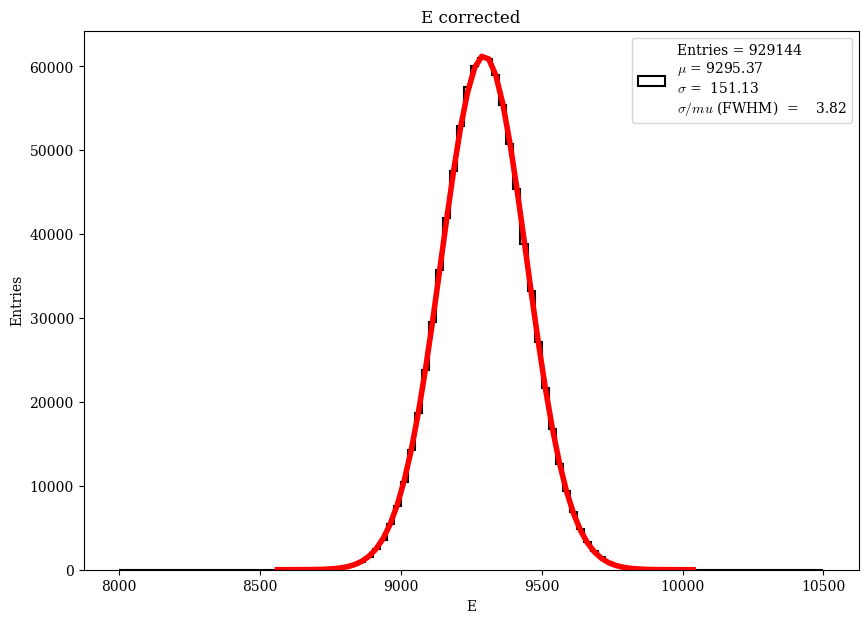

In [53]:
plt.figure(figsize=(10,7))
fc = fit_energy(sel_dst.S2e*corr_tot, nbins=100, range=(8000, 10500), n_sigma=5)
plot_fit_energy(fc)
print_fit_energy(fc)

plt.title('E corrected')
plt.xlabel('E')
plt.ylabel('Entries')
plt.legend(fontsize = 10, loc = 'best')

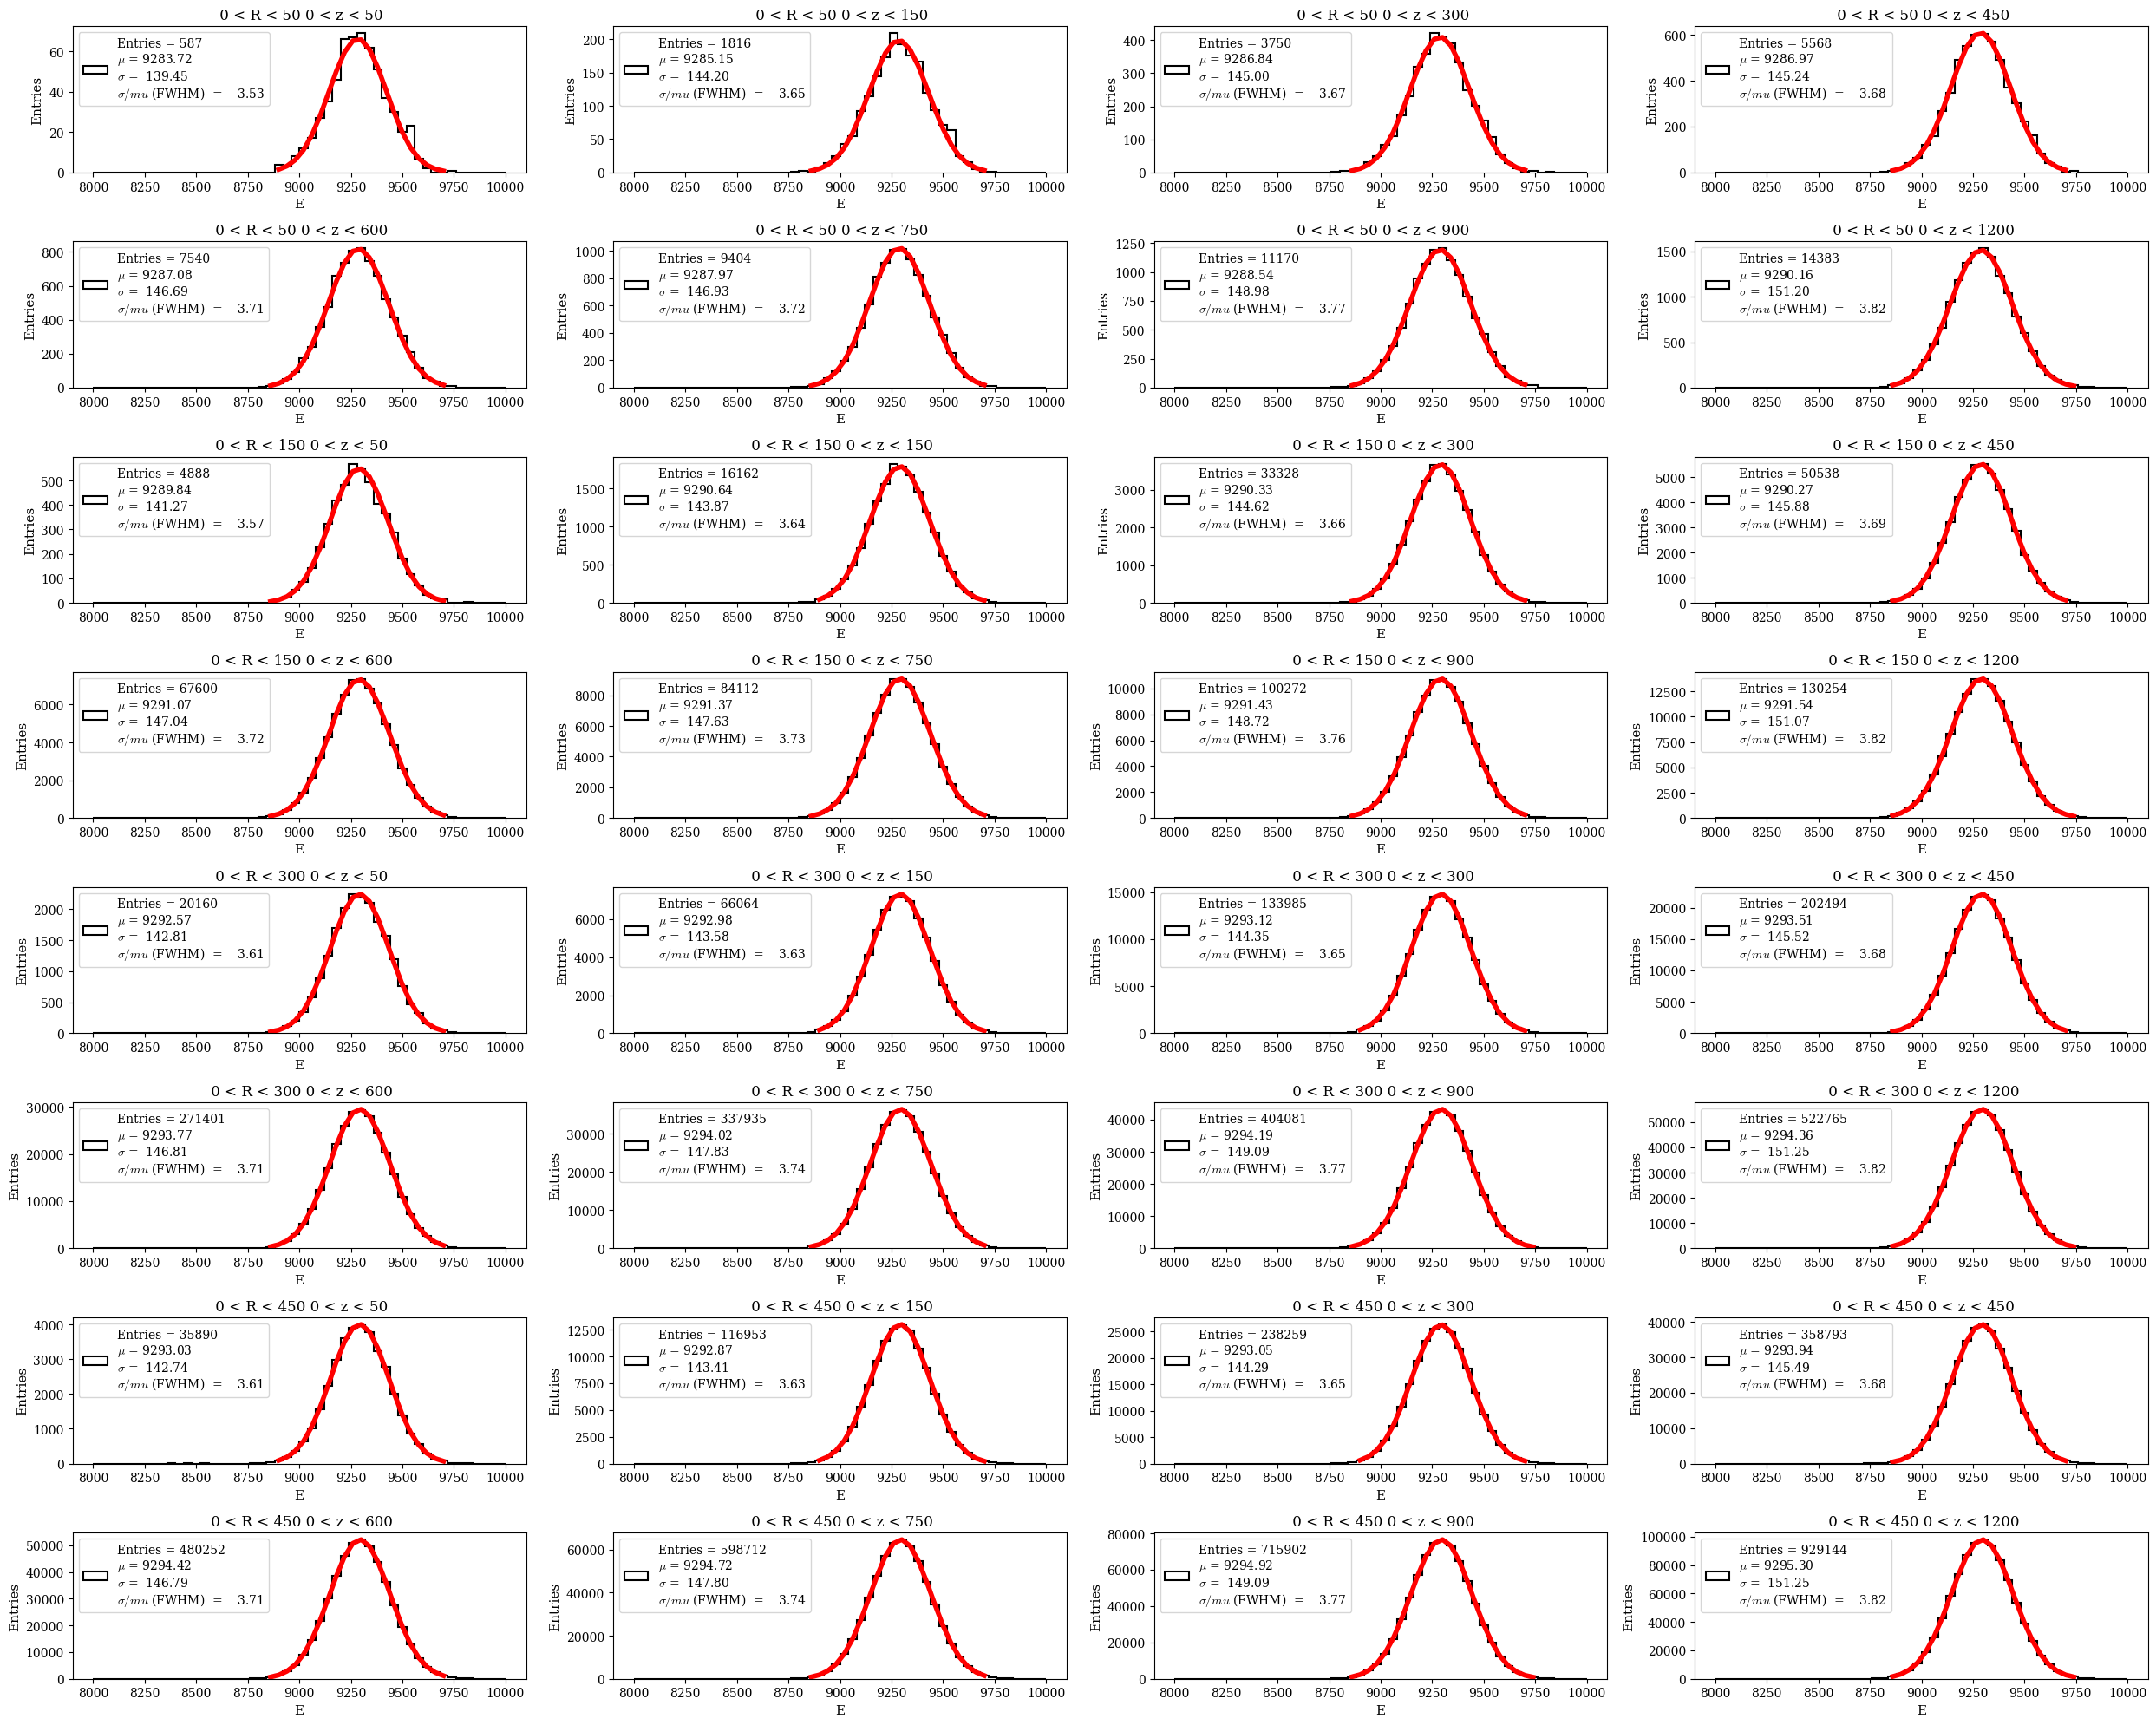

In [54]:
Ri = (50, 150,300,450)
Zi = (50, 150, 300, 450, 600, 750, 900, 1200)

FC, FCE = resolution_r_z(Ri, Zi, sel_dst.R, sel_dst.Z, sel_dst.S2e*corr_tot,
                    enbins = 50,
                    erange = (8000, 10000),
                    ixy = (len(Zi),len(Ri)),
                    fdraw  = True,
                    fprint = False,
                    figsize = (25,20))

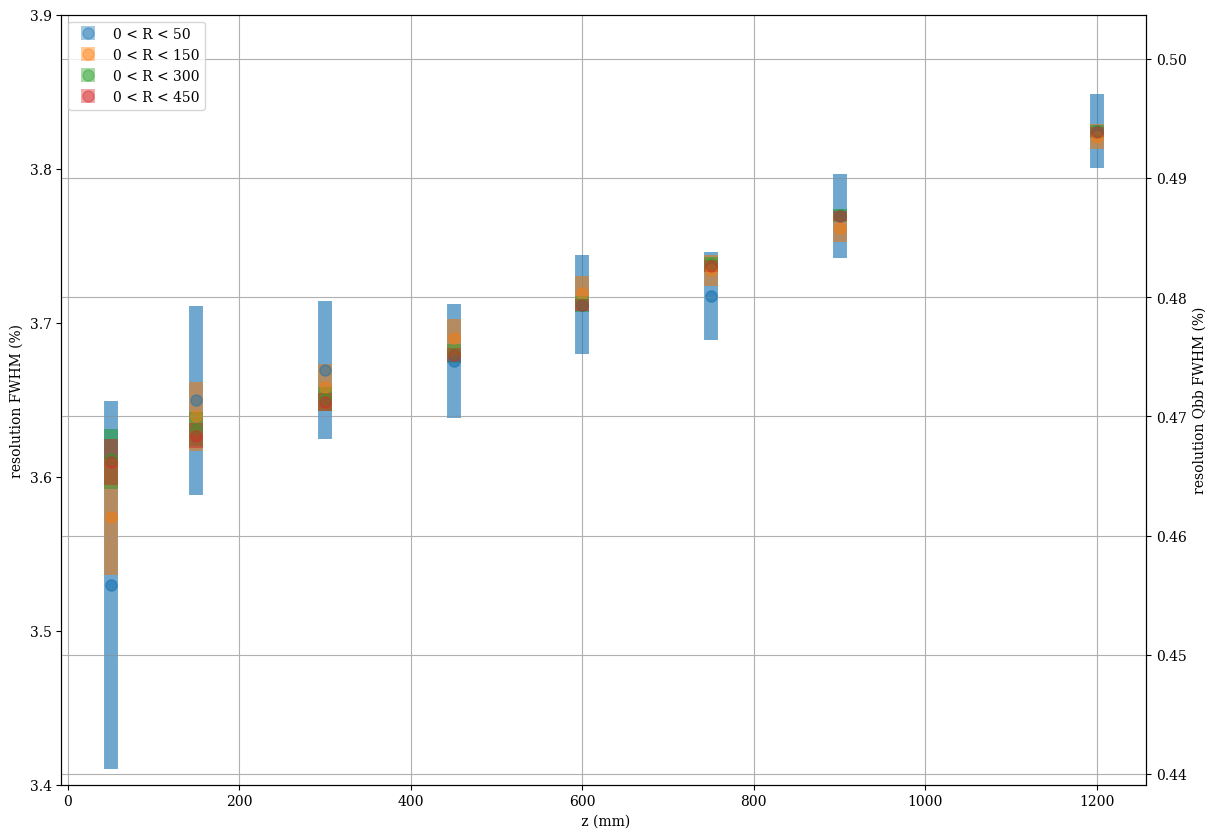

In [55]:
plot_resolution_r_z(Ri, Zi, FC, FCE, r_range=(3.4,3.9))